# 04 – Backtest: decision, auction bids and settlement

This notebook only **loads the outputs** of `.venv/bin/python -m src.backtest.run_backtest` and shows them (re-run that command first; it rewrites everything).
Strategy 4 (`ml_battery`) is our product with the decision rules tuned on data **before October**; 4b is the plain block plan with config defaults; 6 is the **ceiling** (hourly perfect-foresight plan over the whole period).
Check the `demand_source` / `price_source` columns: `standin` means the ML prediction file did not exist yet.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
summary = pd.read_csv('reports/backtest_summary.csv')
print('demand forecast source:', summary['demand_source'].unique(), '| price forecast source:', summary['price_source'].unique())

demand forecast source: <ArrowStringArray>
['ml']
Length: 1, dtype: str | price forecast source: <ArrowStringArray>
['ml']
Length: 1, dtype: str


## Summary per split and strategy (CHF; 'adj' = inventory-adjusted)

In [2]:
cols = ['split','label','total_cost_chf','saving_vs_baseline_chf','saving_vs_baseline_adj_chf','saving_adj_ci_low_chf','saving_adj_ci_high_chf',
        'pct_perfect_captured','battery_value_adj_chf','pct_battery_value_captured','inventory_change_mwh','imbalance_penalty_chf','cycles','days_battery_idle','share_charge_cleared']
summary[summary.split=='test'][cols].round(1)

,split,label,total_cost_chf,saving_vs_baseline_chf,saving_vs_baseline_adj_chf,saving_adj_ci_low_chf,saving_adj_ci_high_chf,pct_perfect_captured,battery_value_adj_chf,pct_battery_value_captured,inventory_change_mwh,imbalance_penalty_chf,cycles,days_battery_idle,share_charge_cleared
0,test,"1 Baseline: naive, no battery",45685820.2,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,314815.7,0.0,31,NaN
1,test,"2 ML demand, no battery",45504786.7,181033.5,181033.5,110713.3,263227.8,48.3,NaN,NaN,0.0,133782.3,0.0,31,NaN
2,test,3 Naive + battery,45651773.5,34046.7,30915.8,8194.7,53613.8,8.2,30915.8,51.5,-16.0,319773.4,26.3,3,0.7
3,test,"4 ML + battery (product, tuned)",45459320.9,226499.3,226499.3,158868.2,306077.3,60.4,45465.8,75.8,0.0,133812.5,30.8,0,1.0
4,test,"4b ML + battery, block plan, defaults",45477015.7,208804.5,208021.8,139322.3,292419.8,55.5,26988.3,45.0,-4.0,134665.7,22.2,0,0.8
5,test,"5 Perfect foresight, same 4-hour block rules",45342699.3,343120.9,343120.9,269758.2,428403.2,91.5,28305.2,47.2,0.0,0.0,23.7,1,1.0
6,test,"6 Perfect foresight, hourly (ceiling)",45311029.2,374791.0,374791.0,297660.7,464903.5,100.0,59975.2,100.0,0.0,0.0,30.6,0,1.0
7,test,"7 Perfect demand, no battery",45371004.5,314815.7,314815.7,240756.6,403725.3,84.0,NaN,NaN,0.0,0.0,0.0,31,NaN


In [3]:
summary[summary.split=='val'][cols].round(1)

,split,label,total_cost_chf,saving_vs_baseline_chf,saving_vs_baseline_adj_chf,saving_adj_ci_low_chf,saving_adj_ci_high_chf,pct_perfect_captured,battery_value_adj_chf,pct_battery_value_captured,inventory_change_mwh,imbalance_penalty_chf,cycles,days_battery_idle,share_charge_cleared
8,val,"1 Baseline: naive, no battery",32883845.1,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,209071.2,0.0,30,NaN
9,val,"2 ML demand, no battery",32764760.6,119084.4,119084.4,79577.7,160847.4,37.8,NaN,NaN,0.0,89986.8,0.0,30,NaN
10,val,3 Naive + battery,32801251.7,82593.3,82593.3,67427.0,98434.2,26.2,82593.3,78.1,0.0,208956.5,29.6,0,1.0
11,val,"4 ML + battery (product, tuned)",32677950.0,205895.0,205895.0,164913.6,246979.4,65.4,86810.6,82.1,0.0,90015.8,29.7,0,1.0
12,val,"4b ML + battery, block plan, defaults",32697450.7,186394.4,186394.4,146663.7,226502.0,59.2,67310.0,63.6,0.0,90260.6,27.1,0,0.9
13,val,"5 Perfect foresight, same 4-hour block rules",32606290.7,277554.4,277554.4,239622.7,319083.6,88.1,68483.2,64.7,0.0,0.0,27.9,0,1.0
14,val,"6 Perfect foresight, hourly (ceiling)",32568977.4,314867.7,314867.7,274352.1,357294.3,100.0,105796.5,100.0,0.0,0.0,29.7,0,1.0
15,val,"7 Perfect demand, no battery",32674773.9,209071.2,209071.2,166527.1,256576.4,66.4,NaN,NaN,0.0,0.0,0.0,30,NaN


In [4]:
summary[summary.split=='rolling'][cols].round(1)

,split,label,total_cost_chf,saving_vs_baseline_chf,saving_vs_baseline_adj_chf,saving_adj_ci_low_chf,saving_adj_ci_high_chf,pct_perfect_captured,battery_value_adj_chf,pct_battery_value_captured,inventory_change_mwh,imbalance_penalty_chf,cycles,days_battery_idle,share_charge_cleared
16,rolling,"1 Baseline: naive, no battery",263503273.4,-0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,2566866.8,0.0,335,NaN
17,rolling,"2 ML demand, no battery",261933484.2,1569789.3,1569789.3,1347423.3,1799763.3,47.8,NaN,NaN,0.0,997077.6,0.0,335,NaN
18,rolling,3 Naive + battery,262956005.3,547268.2,547268.2,481083.4,613566.7,16.7,547268.2,76.0,0.0,2574162.2,307.5,8,0.9
19,rolling,"4 ML + battery (product, tuned)",261326490.1,2176783.3,2176783.3,1954351.0,2419122.0,66.2,606994.1,84.3,0.0,997834.6,321.2,1,1.0
20,rolling,"4b ML + battery, block plan, defaults",261443849.8,2059423.7,2059423.7,1837949.8,2295493.4,62.7,489634.4,68.0,0.0,998268.3,284.9,1,0.9
21,rolling,"5 Perfect foresight, same 4-hour block rules",260441829.7,3061443.7,3061443.7,2815876.3,3319734.1,93.1,494576.9,68.7,0.0,0.0,269.1,11,1.0
22,rolling,"6 Perfect foresight, hourly (ceiling)",260216442.3,3286831.1,3286831.1,3035500.3,3544377.3,100.0,719964.3,100.0,0.0,0.0,323.0,0,1.0
23,rolling,"7 Perfect demand, no battery",260936406.6,2566866.8,2566866.8,2330156.8,2820211.7,78.1,NaN,NaN,0.0,0.0,0.0,335,NaN


## Where does the saving come from?
`total (1−4) = demand-forecast part (1−2) + battery part (2−4)`, and `battery part = plain block plan (2−4b) + tuning / hourly shaping (4b−4)`.

In [5]:
pd.read_csv('reports/backtest_decomposition.csv').set_index('split').T

split,test,val,rolling
demand_source,ml,ml,ml
price_source,ml,ml,ml
total_saving_chf,226499.264601,205895.028927,2176783.344966
total_saving_raw_chf,226499.264601,205895.028927,2176783.344966
demand_forecast_part_chf,181033.474105,119084.426142,1569789.28193
battery_part_chf,45465.790496,86810.602785,606994.063036
block_default_battery_part_chf,26988.330402,67309.97678,489634.375461
tuning_and_shaping_part_chf,18477.460094,19500.626005,117359.687575
ceiling_total_saving_chf,374790.972248,314867.650978,3286831.143073
ceiling_battery_value_chf,59975.246837,105796.467035,719964.298895


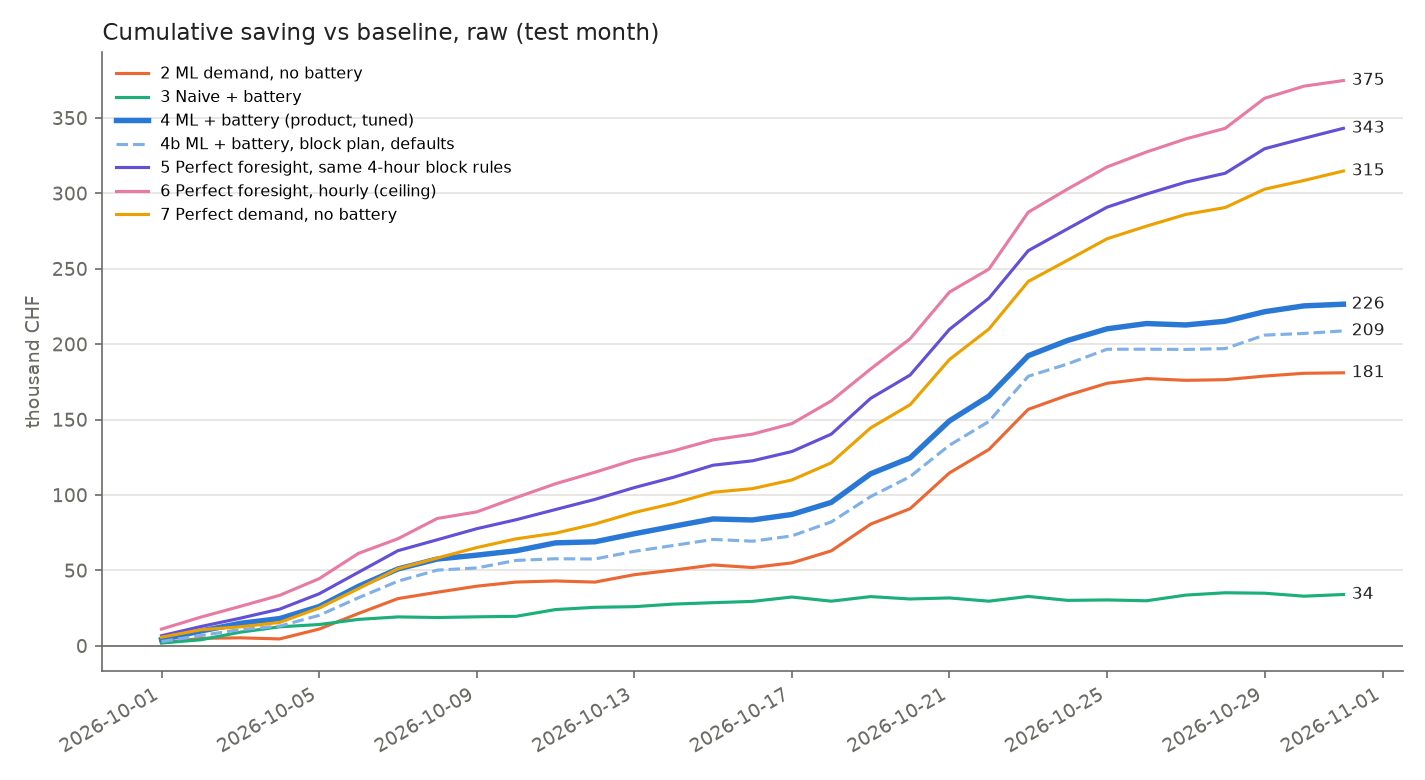

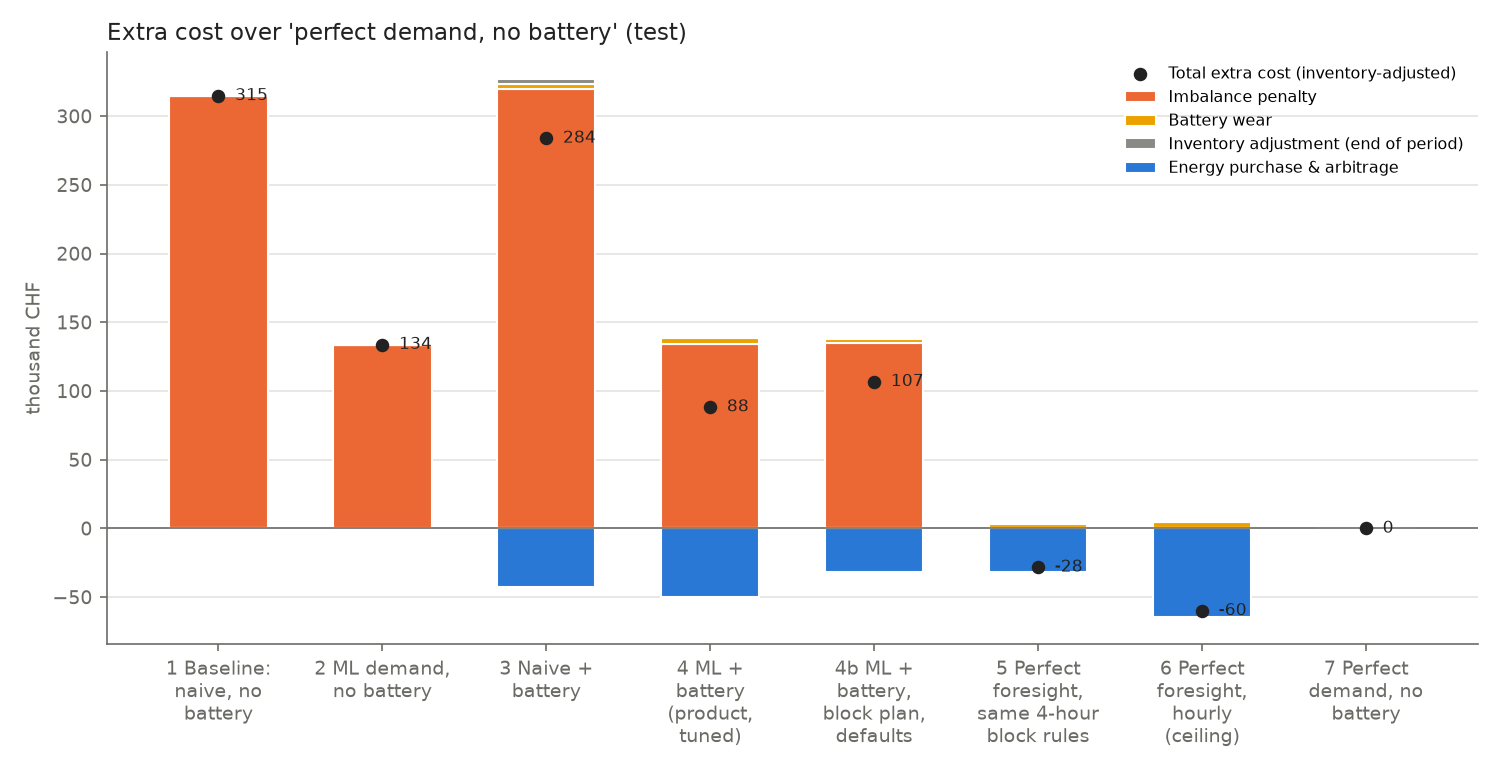

In [6]:
display(Image('reports/figures/backtest_cumulative_savings_test.png'))
display(Image('reports/figures/backtest_cost_breakdown.png'))

## Checks: exceptions to the order ceiling ≤ product ≤ baseline

In [7]:
exc = pd.read_csv('reports/backtest_exceptions.csv')
exc.groupby(['split','check','reason']).size().rename('days').reset_index()

,split,check,reason,days
0,rolling,block_oracle(5) > ml_battery,charge-level carry-over: ml_battery took more ...,2
1,rolling,block_oracle(5) > ml_battery,hourly prices inside the blocks: the block ora...,3
2,rolling,ceiling(6) > ml_battery,inter-day shift: the ceiling plans the whole p...,4
3,rolling,ml_battery > baseline,battery refill / stock-up: energy bought today...,4
4,rolling,ml_battery > baseline,demand forecast: the ML demand forecast was fu...,19
5,rolling,ml_battery > baseline,price forecast: the forecast spread between ho...,1
6,test,ceiling(6) > ml_battery,inter-day shift: the ceiling plans the whole p...,2
7,test,ml_battery > baseline,demand forecast: the ML demand forecast was fu...,2
8,val,ceiling(6) > ml_battery,inter-day shift: the ceiling plans the whole p...,2
9,val,ml_battery > baseline,demand forecast: the ML demand forecast was fu...,1


## Decision tuning (rolling period + 1–29 September only; October never used)

In [8]:
tun = pd.read_csv('reports/decision_tuning.csv')
tun[['stage','candidate','saving_rolling_chf','saving_sept_chf','saving_combined_chf','vs_reference_chf',
     'vs_reference_ci_low_chf','vs_reference_ci_high_chf','is_default','stage_winner','chosen']].sort_values(['stage','saving_combined_chf'], ascending=[True, False]).round(0)

,stage,candidate,saving_rolling_chf,saving_sept_chf,saving_combined_chf,vs_reference_chf,vs_reference_ci_low_chf,vs_reference_ci_high_chf,is_default,stage_winner,chosen
8,1,"hourly_shape(7d, same day type), limit 0.9, ma...",2176783.0,197252.0,2374035.0,135803.0,107951.0,163697.0,False,True,False
9,1,"hourly_shape(7d, same day type), limit 0.9, ma...",2176439.0,197161.0,2373601.0,135369.0,108260.0,162490.0,False,False,False
10,1,"hourly_shape(7d, same day type), limit 0.9, ma...",2173392.0,197163.0,2370555.0,132323.0,104552.0,159277.0,False,False,False
4,1,"hourly_shape(7d), limit 0.9, margin 0 EUR/MWh,...",2172362.0,196619.0,2368981.0,130750.0,103479.0,156957.0,False,False,False
5,1,"hourly_shape(7d), limit 0.9, margin 5 EUR/MWh,...",2170877.0,196619.0,2367497.0,129265.0,102306.0,154686.0,False,False,False
12,1,"hourly_shape(14d), limit 0.9, margin 0 EUR/MWh...",2169028.0,198164.0,2367192.0,128960.0,102252.0,155566.0,False,False,False
6,1,"hourly_shape(7d), limit 0.9, margin 10 EUR/MWh...",2169308.0,196483.0,2365791.0,127559.0,99945.0,153505.0,False,False,False
13,1,"hourly_shape(14d), limit 0.9, margin 5 EUR/MWh...",2167434.0,198164.0,2365598.0,127366.0,100734.0,153133.0,False,False,False
14,1,"hourly_shape(14d), limit 0.9, margin 10 EUR/MW...",2165753.0,197988.0,2363740.0,125509.0,98726.0,151643.0,False,False,False
11,1,"hourly_shape(7d, same day type), limit 0.9, ma...",2160370.0,197113.0,2357483.0,119252.0,89567.0,145583.0,False,False,False


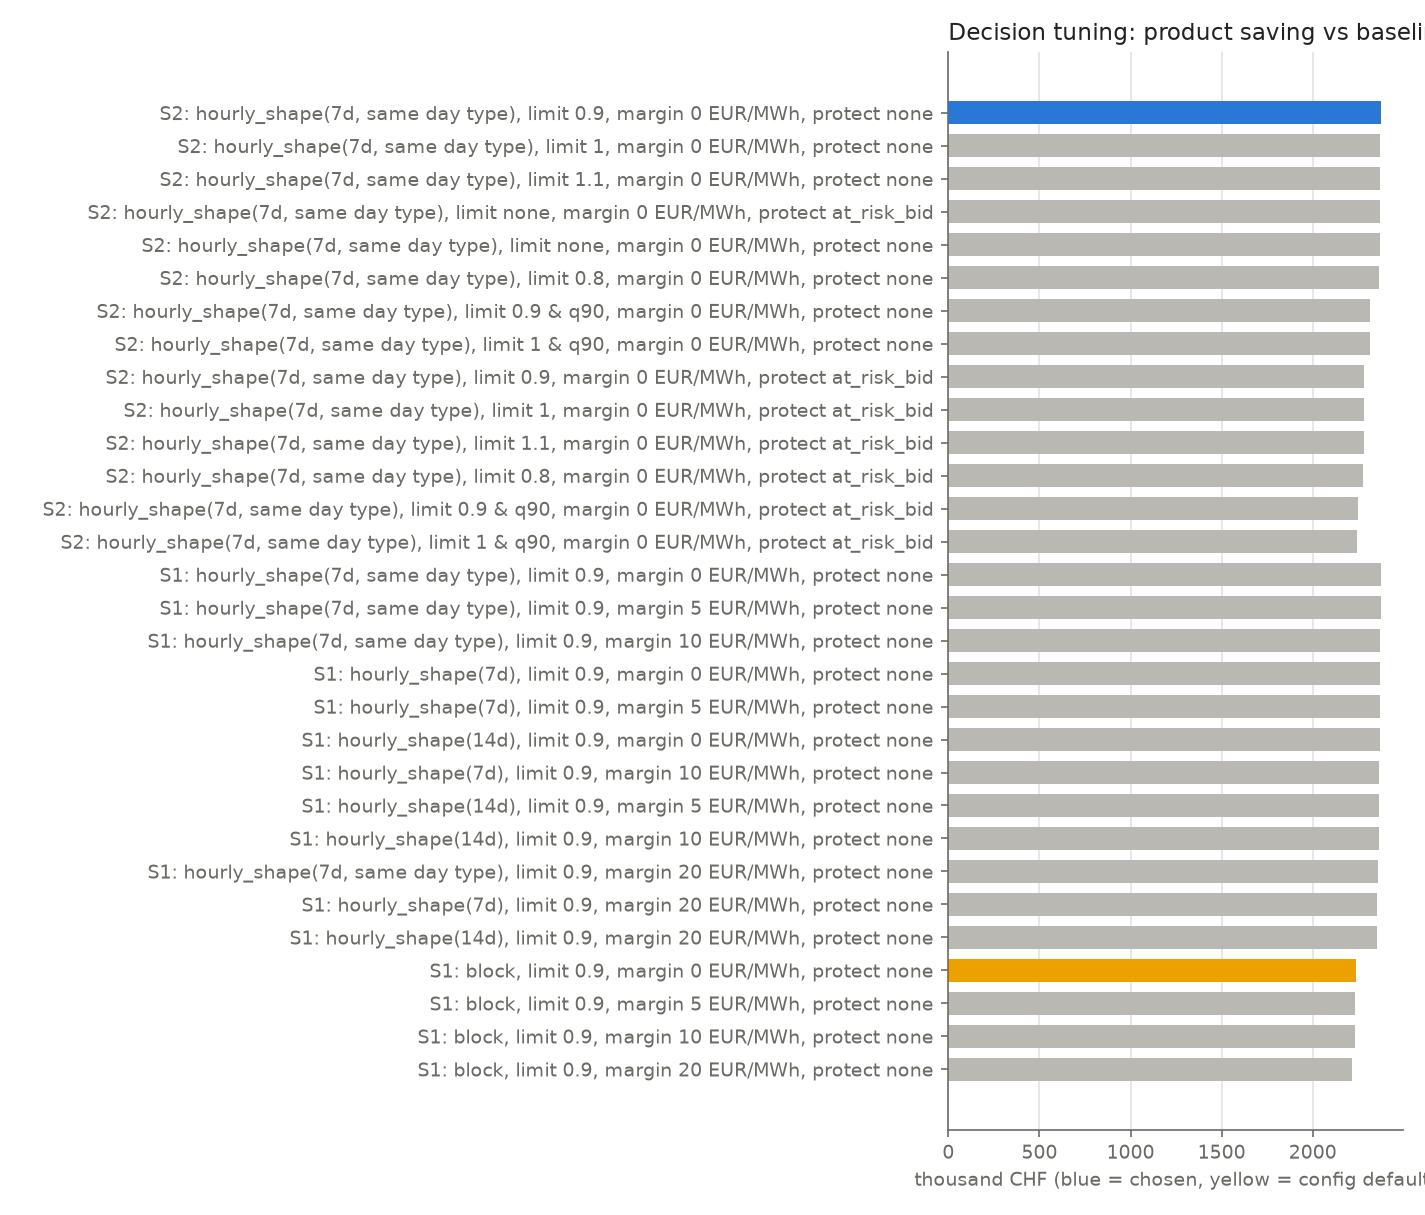

In [9]:
display(Image('reports/figures/backtest_decision_tuning.png'))

## Sensitivities (test month, for information)

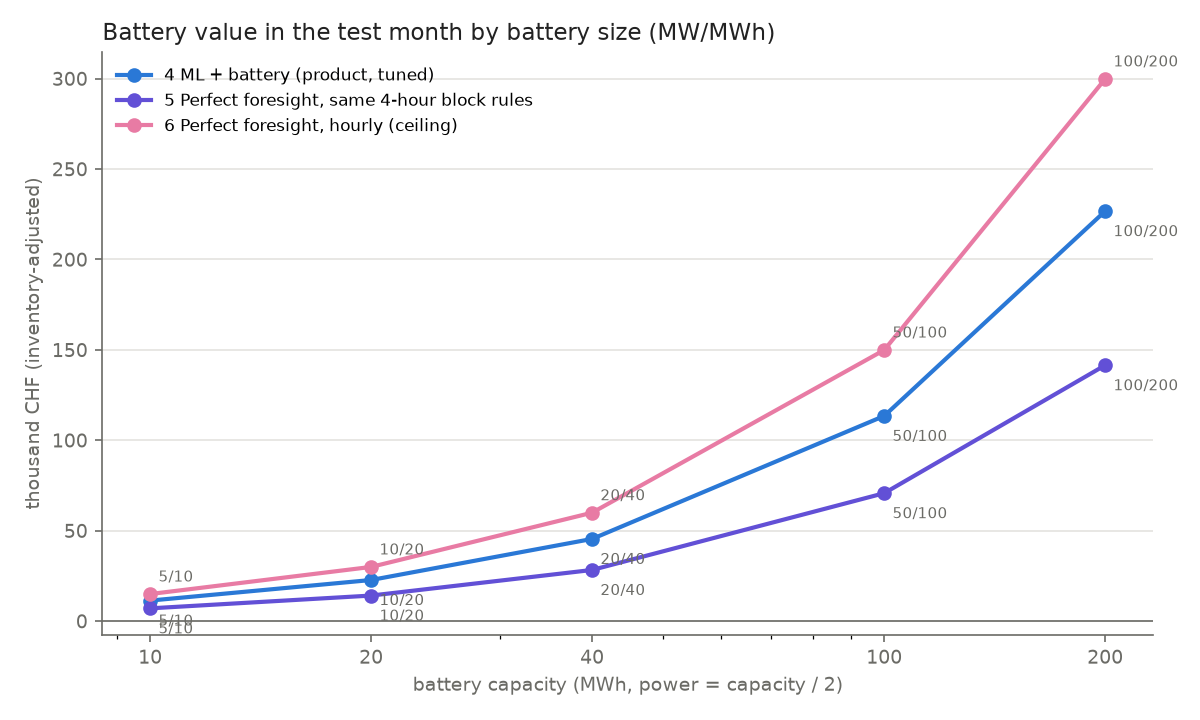

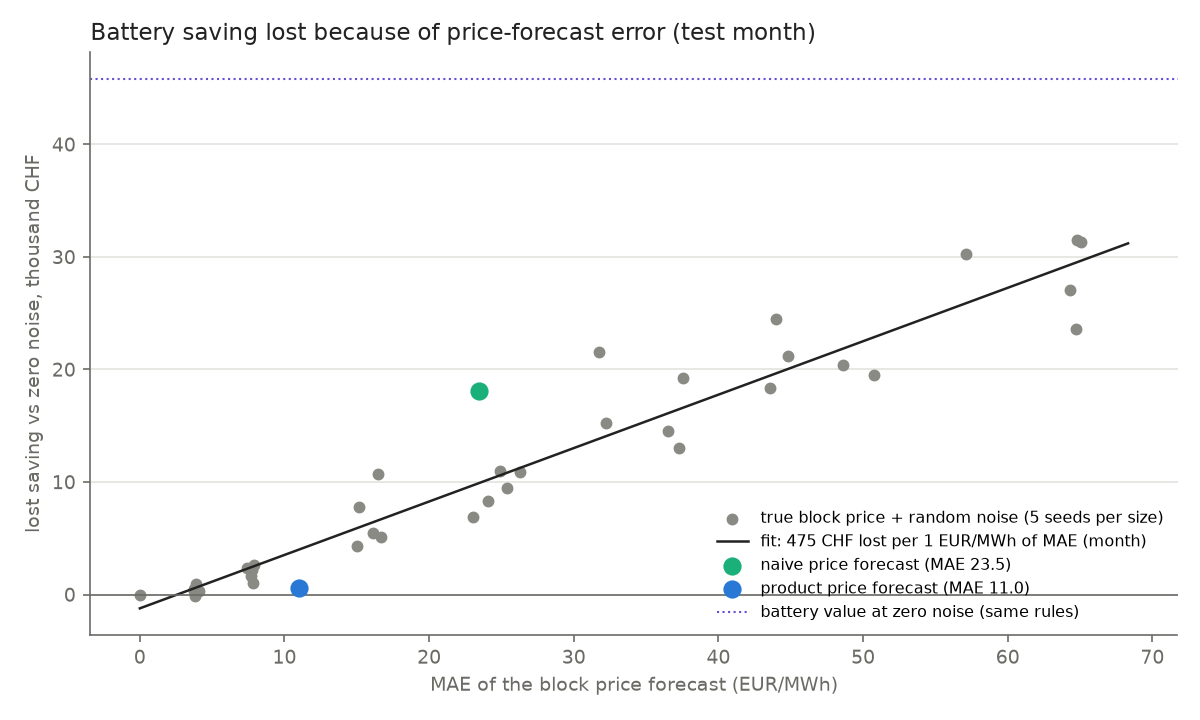

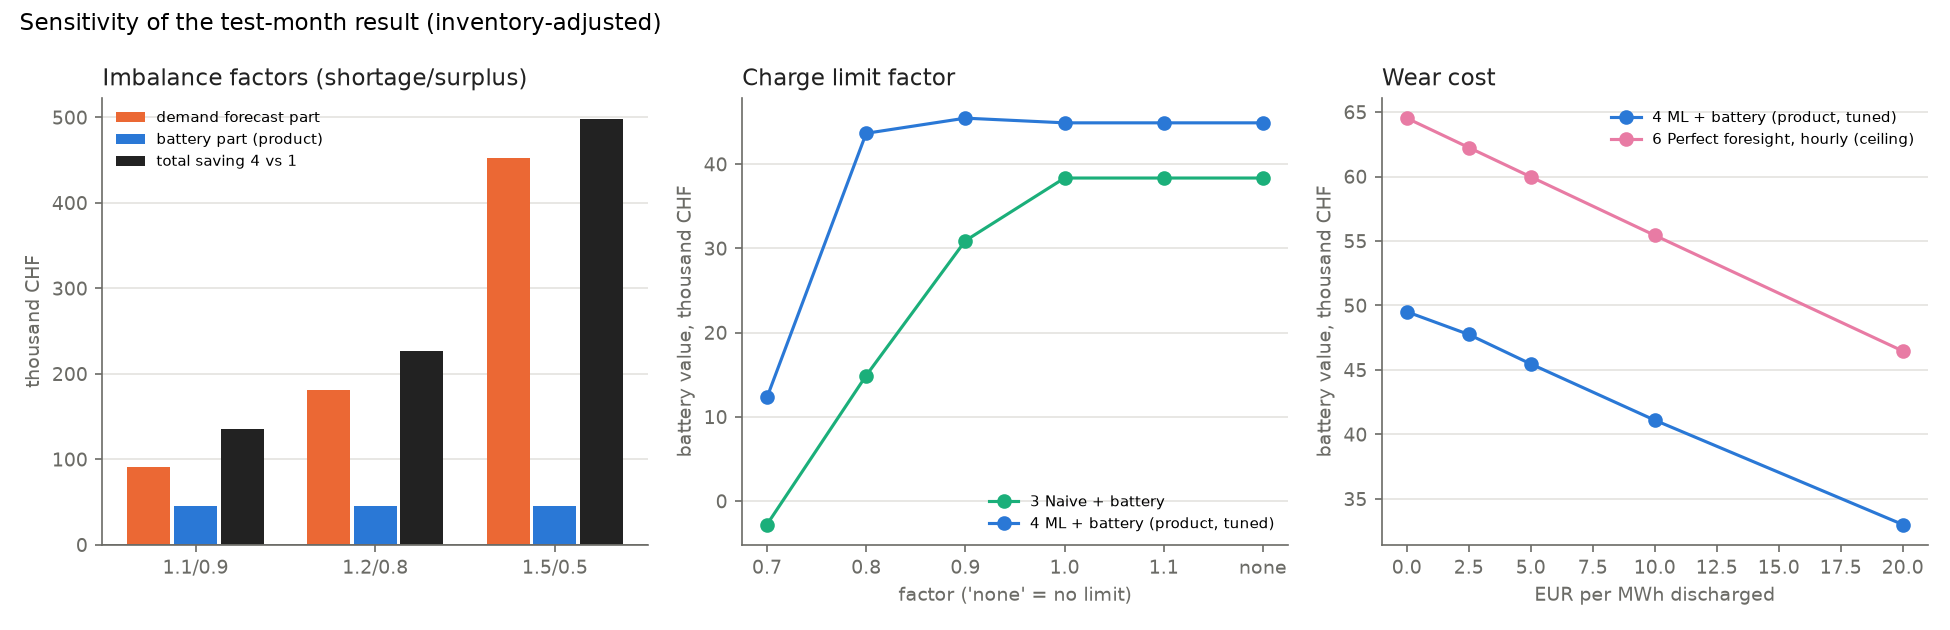

In [10]:
display(Image('reports/figures/backtest_battery_size_sensitivity.png'))
display(Image('reports/figures/backtest_price_error_sensitivity.png'))
display(Image('reports/figures/backtest_decision_sensitivity.png'))

## One day in detail: 6-block decision table, hourly bids and settlement

In [11]:
from src.backtest.run_backtest import plan_day, tuned_decision
from src.decision.bids import bids_table
dec = tuned_decision(); print('decision:', dec.describe())
r = plan_day('2026-10-14', 'ml_battery', decision=dec)
display(r['plan'].round(2))
display(bids_table(r['bids']).head(10))
{k: (round(v, 1) if isinstance(v, float) else v) for k, v in r['summary'].items()}

decision: hourly_shape(7d, same day type), limit 0.9, margin 0 EUR/MWh, protect none


,period,block,hours,demand_mwh,price_eur_mwh,buy_mwh,charge_mwh,discharge_mwh,sell_mwh,soc_mwh,option,charge_limit_eur_mwh
0,0,0,4.0,859.48,187.46,876.34,16.87,0.0,0.0,36.00,buy_and_store,223.94
1,1,1,4.0,999.62,211.70,999.62,0.00,0.0,0.0,36.00,buy,NaN
2,2,2,4.0,1385.66,218.34,1373.66,0.00,12.0,0.0,23.35,use_storage_and_buy,NaN
3,3,3,4.0,1351.95,188.51,1365.28,13.33,0.0,0.0,36.00,buy_and_store,230.81
4,4,4,4.0,1339.85,244.31,1319.85,0.00,20.0,0.0,14.92,use_storage_and_buy,NaN
5,5,5,4.0,1116.15,220.61,1121.51,5.36,0.0,0.0,20.00,buy_and_store,223.94


,Date,Hour (local),Block,Demand bid MWh (price-independent),Charge bid MWh,Charge limit EUR/MWh,Total bid MWh
0,2026-10-14,00:00 (UTC+02),00-04,231.365,0.000,-,231.365
1,2026-10-14,01:00 (UTC+02),00-04,212.303,0.000,-,212.303
2,2026-10-14,02:00 (UTC+02),00-04,212.516,0.000,-,212.516
3,2026-10-14,03:00 (UTC+02),00-04,203.293,16.865,223.94,220.159
4,2026-10-14,04:00 (UTC+02),04-08,203.078,0.000,-,203.078
5,2026-10-14,05:00 (UTC+02),04-08,223.165,0.000,-,223.165
6,2026-10-14,06:00 (UTC+02),04-08,265.442,0.000,-,265.442
7,2026-10-14,07:00 (UTC+02),04-08,307.933,0.000,-,307.933
8,2026-10-14,08:00 (UTC+02),08-12,323.979,0.000,-,323.979
9,2026-10-14,09:00 (UTC+02),08-12,343.700,0.000,-,343.700


{'delivery_date': datetime.date(2026, 10, 14),
 'strategy': 'ml_battery',
 'decision': 'hourly_shape(7d, same day type), limit 0.9, margin 0 EUR/MWh, protect none',
 'n_hours': 24,
 'actual_price_mean_eur_mwh': 216.2,
 'eurchf_mean': 0.9,
 'eta_discharge': 0.9,
 'forecast_demand_mwh': 7052.7,
 'actual_demand_mwh': 7050.9,
 'demand_bid_mwh': 7020.7,
 'at_risk_bid_mwh': 0.0,
 'charge_bid_mwh': 35.6,
 'charge_cleared_mwh': 35.6,
 'share_charge_cleared': 1.0,
 'energy_bought_mwh': 7056.3,
 'charged_mwh': 35.6,
 'planned_discharge_mwh': 32.0,
 'discharged_mwh': 32.0,
 'discharge_not_delivered_mwh': 0.0,
 'cycles': 1.0,
 'battery_idle': False,
 'plan_has_discharge': True,
 'shortage_mwh': 33.8,
 'surplus_mwh': 35.6,
 'soc_start_mwh': 20.0,
 'soc_end_mwh': np.float64(20.0),
 'soc_target_relaxed': False,
 'da_cost_eur': 1541119.7,
 'imbalance_cost_eur': 4312.1,
 'imbalance_penalty_eur': 3195.5,
 'wear_cost_eur': 160.0,
 'total_cost_eur': 1545591.8,
 'da_cost_chf': 1437864.7,
 'imbalance_cost_c

## Notes written by the backtest run

In [12]:
display(Markdown(open('reports/backtest_notes.md', encoding='utf-8').read()))

# Backtest notes

*Regenerated by `.venv/bin/python -m src.backtest.run_backtest` on every run. Do not edit by hand.*

## Which forecasts were used

- **Demand forecast:** ML (`pred_best` from `reports/predictions_demand.parquet`).
- **Price forecast:** ML (`pred_best` from `reports/predictions_price.parquet`).

## How the money is counted

- All money in CHF (hourly EUR x ECB EUR/CHF rate of the day). Cost = day-ahead purchases + imbalance settlement + battery wear (5 EUR per MWh discharged).
- **Imbalance price** (p = actual day-ahead price of the hour): a shortage costs **p + 0.20 x |p|** per MWh, a surplus is sold for **p - 0.20 x |p|** per MWh (shortage factor 1.2, surplus factor 0.8; |p| keeps it a penalty at negative prices). These are assumptions, not Swissgrid's real imbalance prices.
- Every strategy starts each period with the battery at 20 MWh. Because strategies end the period with different amounts of energy in the battery, we also report an **inventory-adjusted** cost: energy left in the battery at the end minus at the start (MWh) x discharge efficiency (0.949) x the period's mean actual day-ahead price, subtracted from the cost. Savings are shown raw and adjusted; '% of ceiling' uses the adjusted numbers.
- **Ceiling (6)** = one hourly perfect-foresight plan over the WHOLE period, ending with the same charge level it started with, physical wear only, no limits or margins. It is a true lower bound on cost: no strategy that follows the same battery rules can be cheaper over the period. **(5)** is perfect foresight with the same 4-hour block rules as the product (uniform dispatch inside a block, back to the start level every evening); it is NOT a ceiling.
- CI = 95 % paired day-bootstrap interval (1000 draws) of the saving vs strategy 1.

## Test month (October 2026)

Demand forecast: **ML**; price forecast: **ML**.

| strategy | total cost CHF | saving vs 1 (raw) | saving vs 1 (adj.) | CI low | CI high | % of ceiling | battery value (adj.) | % of ceiling battery value | imbalance penalty | stock change MWh | cycles | idle days | charge cleared |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 Baseline: naive, no battery | 45,685,820 | 0 | 0 | 0 | 0 | 0% |  |  | 314,816 | +0.0 | 0.0 | 31 |  |
| 2 ML demand, no battery | 45,504,787 | 181,033 | 181,033 | 110,713 | 263,228 | 48% |  |  | 133,782 | +0.0 | 0.0 | 31 |  |
| 3 Naive + battery | 45,651,773 | 34,047 | 30,916 | 8,195 | 53,614 | 8% | 30,916 | 52% | 319,773 | -16.0 | 26.3 | 3 | 73% |
| 4 ML + battery (product, tuned) | 45,459,321 | 226,499 | 226,499 | 158,868 | 306,077 | 60% | 45,466 | 76% | 133,812 | +0.0 | 30.8 | 0 | 98% |
| 4b ML + battery, block plan, defaults | 45,477,016 | 208,805 | 208,022 | 139,322 | 292,420 | 56% | 26,988 | 45% | 134,666 | -4.0 | 22.2 | 0 | 84% |
| 5 Perfect foresight, same 4-hour block rules | 45,342,699 | 343,121 | 343,121 | 269,758 | 428,403 | 92% | 28,305 | 47% | 0 | +0.0 | 23.7 | 1 | 100% |
| 6 Perfect foresight, hourly (ceiling) | 45,311,029 | 374,791 | 374,791 | 297,661 | 464,903 | 100% | 59,975 | 100% | 0 | +0.0 | 30.6 | 0 | 100% |
| 7 Perfect demand, no battery | 45,371,004 | 314,816 | 314,816 | 240,757 | 403,725 | 84% |  |  | 0 | +0.0 | 0.0 | 31 |  |

- Saving of the product (4) vs baseline (1), inventory-adjusted: **CHF 226,499** (raw CHF 226,499) = better demand forecast (1-2) CHF 181,033 + battery (2-4) CHF 45,466.
  - of the battery part: plain block plan with defaults (2-4b) CHF 26,988, added by the tuned rules / hourly shaping (4b-4) CHF 18,477.
- The ceiling (6) would save CHF 374,791; the product captures **60%** of it. Of the ceiling's battery value (7-6 = CHF 59,975) the product's battery captures **76%**.
- Cost of demand-forecast errors (vs perfect demand, no battery): naive CHF 314,816, ML CHF 133,782.
- The 4-hour block rules cost CHF 31,670 of battery value even with perfect foresight (5 vs 6; block-rule battery value CHF 28,305).

## Validation month (September 2026)

Demand forecast: **ML**; price forecast: **ML**.

| strategy | total cost CHF | saving vs 1 (raw) | saving vs 1 (adj.) | CI low | CI high | % of ceiling | battery value (adj.) | % of ceiling battery value | imbalance penalty | stock change MWh | cycles | idle days | charge cleared |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 Baseline: naive, no battery | 32,883,845 | 0 | 0 | 0 | 0 | 0% |  |  | 209,071 | +0.0 | 0.0 | 30 |  |
| 2 ML demand, no battery | 32,764,761 | 119,084 | 119,084 | 79,578 | 160,847 | 38% |  |  | 89,987 | +0.0 | 0.0 | 30 |  |
| 3 Naive + battery | 32,801,252 | 82,593 | 82,593 | 67,427 | 98,434 | 26% | 82,593 | 78% | 208,957 | +0.0 | 29.6 | 0 | 99% |
| 4 ML + battery (product, tuned) | 32,677,950 | 205,895 | 205,895 | 164,914 | 246,979 | 65% | 86,811 | 82% | 90,016 | +0.0 | 29.7 | 0 | 99% |
| 4b ML + battery, block plan, defaults | 32,697,451 | 186,394 | 186,394 | 146,664 | 226,502 | 59% | 67,310 | 64% | 90,261 | +0.0 | 27.1 | 0 | 95% |
| 5 Perfect foresight, same 4-hour block rules | 32,606,291 | 277,554 | 277,554 | 239,623 | 319,084 | 88% | 68,483 | 65% | 0 | +0.0 | 27.9 | 0 | 100% |
| 6 Perfect foresight, hourly (ceiling) | 32,568,977 | 314,868 | 314,868 | 274,352 | 357,294 | 100% | 105,796 | 100% | 0 | +0.0 | 29.7 | 0 | 100% |
| 7 Perfect demand, no battery | 32,674,774 | 209,071 | 209,071 | 166,527 | 256,576 | 66% |  |  | 0 | +0.0 | 0.0 | 30 |  |

- Saving of the product (4) vs baseline (1), inventory-adjusted: **CHF 205,895** (raw CHF 205,895) = better demand forecast (1-2) CHF 119,084 + battery (2-4) CHF 86,811.
  - of the battery part: plain block plan with defaults (2-4b) CHF 67,310, added by the tuned rules / hourly shaping (4b-4) CHF 19,501.
- The ceiling (6) would save CHF 314,868; the product captures **65%** of it. Of the ceiling's battery value (7-6 = CHF 105,796) the product's battery captures **82%**.
- Cost of demand-forecast errors (vs perfect demand, no battery): naive CHF 209,071, ML CHF 89,987.
- The 4-hour block rules cost CHF 37,313 of battery value even with perfect foresight (5 vs 6; block-rule battery value CHF 68,483).

## Rolling period (2025-10-01 to 2026-08-31)

Demand forecast: **ML**; price forecast: **ML**.

| strategy | total cost CHF | saving vs 1 (raw) | saving vs 1 (adj.) | CI low | CI high | % of ceiling | battery value (adj.) | % of ceiling battery value | imbalance penalty | stock change MWh | cycles | idle days | charge cleared |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 Baseline: naive, no battery | 263,503,273 | 0 | 0 | 0 | 0 | 0% |  |  | 2,566,867 | +0.0 | 0.0 | 335 |  |
| 2 ML demand, no battery | 261,933,484 | 1,569,789 | 1,569,789 | 1,347,423 | 1,799,763 | 48% |  |  | 997,078 | +0.0 | 0.0 | 335 |  |
| 3 Naive + battery | 262,956,005 | 547,268 | 547,268 | 481,083 | 613,567 | 17% | 547,268 | 76% | 2,574,162 | +0.0 | 307.5 | 8 | 91% |
| 4 ML + battery (product, tuned) | 261,326,490 | 2,176,783 | 2,176,783 | 1,954,351 | 2,419,122 | 66% | 606,994 | 84% | 997,835 | +0.0 | 321.2 | 1 | 97% |
| 4b ML + battery, block plan, defaults | 261,443,850 | 2,059,424 | 2,059,424 | 1,837,950 | 2,295,493 | 63% | 489,634 | 68% | 998,268 | +0.0 | 284.9 | 1 | 93% |
| 5 Perfect foresight, same 4-hour block rules | 260,441,830 | 3,061,444 | 3,061,444 | 2,815,876 | 3,319,734 | 93% | 494,577 | 69% | 0 | +0.0 | 269.1 | 11 | 100% |
| 6 Perfect foresight, hourly (ceiling) | 260,216,442 | 3,286,831 | 3,286,831 | 3,035,500 | 3,544,377 | 100% | 719,964 | 100% | 0 | +0.0 | 323.0 | 0 | 100% |
| 7 Perfect demand, no battery | 260,936,407 | 2,566,867 | 2,566,867 | 2,330,157 | 2,820,212 | 78% |  |  | 0 | +0.0 | 0.0 | 335 |  |

- Saving of the product (4) vs baseline (1), inventory-adjusted: **CHF 2,176,783** (raw CHF 2,176,783) = better demand forecast (1-2) CHF 1,569,789 + battery (2-4) CHF 606,994.
  - of the battery part: plain block plan with defaults (2-4b) CHF 489,634, added by the tuned rules / hourly shaping (4b-4) CHF 117,360.
- The ceiling (6) would save CHF 3,286,831; the product captures **66%** of it. Of the ceiling's battery value (7-6 = CHF 719,964) the product's battery captures **84%**.
- Cost of demand-forecast errors (vs perfect demand, no battery): naive CHF 2,566,867, ML CHF 997,078.
- The 4-hour block rules cost CHF 225,387 of battery value even with perfect foresight (5 vs 6; block-rule battery value CHF 494,577).

Note: the decision rules were tuned on the rolling period plus September 1-29, so the September and rolling numbers are in-sample for those rules (the forecasts themselves are out-of-sample). Only October is a clean test of the rules.

## Decision tuning (data before October only)

Tuned ONCE for the test month on the rolling period (335 days) plus September up to 2026-09-29 (29 days): the settlement of these days was known when the first October day was planned (30 Sept, 10:00). October is never used. Objective = the product's inventory-adjusted saving vs the baseline, summed over both periods.

Stage 1 compares the planning resolution (block plan vs hourly plan with a typical hourly price shape of the last 7 or 14 days, all days or same day type) x the minimum spread margin. Stage 2 takes the stage-1 winner and compares the charge-limit rule (factor 0.8-1.1, no limit, q90 cap) x the protection bid. A candidate replaces the stage reference only if it CLEARLY wins (combined saving higher AND the 95 % paired-bootstrap interval of the improvement above zero).

**Chosen: hourly_shape(7d, same day type), limit 0.9, margin 0 EUR/MWh, protect none.** Used for strategies 3 and 4 in all periods.

| stage | candidate | saving rolling | saving Sept 1-29 | combined | vs stage ref. | CI low | CI high | is_default | stage_winner | chosen |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | hourly_shape(7d, same day type), limit 0.9, margin 0 EUR/MWh, protect none | 2,176,783 | 197,252 | 2,374,035 | 135,803 | 107,951 | 163,697 |  | yes |  |
| 1 | hourly_shape(7d, same day type), limit 0.9, margin 5 EUR/MWh, protect none | 2,176,439 | 197,161 | 2,373,601 | 135,369 | 108,260 | 162,490 |  |  |  |
| 1 | hourly_shape(7d, same day type), limit 0.9, margin 10 EUR/MWh, protect none | 2,173,392 | 197,163 | 2,370,555 | 132,323 | 104,552 | 159,277 |  |  |  |
| 1 | hourly_shape(7d), limit 0.9, margin 0 EUR/MWh, protect none | 2,172,362 | 196,619 | 2,368,981 | 130,750 | 103,479 | 156,957 |  |  |  |
| 1 | hourly_shape(7d), limit 0.9, margin 5 EUR/MWh, protect none | 2,170,877 | 196,619 | 2,367,497 | 129,265 | 102,306 | 154,686 |  |  |  |
| 1 | hourly_shape(14d), limit 0.9, margin 0 EUR/MWh, protect none | 2,169,028 | 198,164 | 2,367,192 | 128,960 | 102,252 | 155,566 |  |  |  |
| 1 | hourly_shape(7d), limit 0.9, margin 10 EUR/MWh, protect none | 2,169,308 | 196,483 | 2,365,791 | 127,559 | 99,945 | 153,505 |  |  |  |
| 1 | hourly_shape(14d), limit 0.9, margin 5 EUR/MWh, protect none | 2,167,434 | 198,164 | 2,365,598 | 127,366 | 100,734 | 153,133 |  |  |  |
| 1 | hourly_shape(14d), limit 0.9, margin 10 EUR/MWh, protect none | 2,165,753 | 197,988 | 2,363,740 | 125,509 | 98,726 | 151,643 |  |  |  |
| 1 | hourly_shape(7d, same day type), limit 0.9, margin 20 EUR/MWh, protect none | 2,160,370 | 197,113 | 2,357,483 | 119,252 | 89,567 | 145,583 |  |  |  |
| 1 | hourly_shape(7d), limit 0.9, margin 20 EUR/MWh, protect none | 2,155,231 | 196,390 | 2,351,620 | 113,389 | 85,364 | 139,758 |  |  |  |
| 1 | hourly_shape(14d), limit 0.9, margin 20 EUR/MWh, protect none | 2,152,826 | 197,940 | 2,350,766 | 112,534 | 84,493 | 140,518 |  |  |  |
| 1 | block, limit 0.9, margin 0 EUR/MWh, protect none | 2,059,424 | 178,808 | 2,238,232 | 0 | 0 | 0 | yes |  |  |
| 1 | block, limit 0.9, margin 5 EUR/MWh, protect none | 2,055,527 | 178,880 | 2,234,407 | -3,825 | -17,298 | 8,746 |  |  |  |
| 1 | block, limit 0.9, margin 10 EUR/MWh, protect none | 2,050,584 | 178,886 | 2,229,470 | -8,761 | -24,677 | 5,898 |  |  |  |
| 1 | block, limit 0.9, margin 20 EUR/MWh, protect none | 2,037,309 | 178,842 | 2,216,151 | -22,081 | -40,225 | -4,935 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 0.9, margin 0 EUR/MWh, protect none | 2,176,783 | 197,252 | 2,374,035 | 0 | 0 | 0 |  | yes | yes |
| 2 | hourly_shape(7d, same day type), limit 1, margin 0 EUR/MWh, protect none | 2,174,767 | 197,157 | 2,371,925 | -2,110 | -15,464 | 11,831 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 1.1, margin 0 EUR/MWh, protect none | 2,174,543 | 197,122 | 2,371,665 | -2,370 | -16,288 | 11,550 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit none, margin 0 EUR/MWh, protect none | 2,174,493 | 197,122 | 2,371,615 | -2,420 | -16,143 | 11,506 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit none, margin 0 EUR/MWh, protect at_risk_bid | 2,174,493 | 197,122 | 2,371,615 | -2,420 | -16,143 | 11,506 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 0.8, margin 0 EUR/MWh, protect none | 2,168,771 | 197,274 | 2,366,045 | -7,990 | -37,676 | 20,798 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 0.9 & q90, margin 0 EUR/MWh, protect none | 2,125,781 | 190,030 | 2,315,811 | -58,224 | -93,447 | -25,244 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 1 & q90, margin 0 EUR/MWh, protect none | 2,123,458 | 189,979 | 2,313,437 | -60,598 | -95,414 | -27,242 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 0.9, margin 0 EUR/MWh, protect at_risk_bid | 2,097,379 | 186,338 | 2,283,717 | -90,318 | -101,257 | -79,154 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 1, margin 0 EUR/MWh, protect at_risk_bid | 2,096,040 | 186,161 | 2,282,201 | -91,834 | -109,750 | -74,832 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 1.1, margin 0 EUR/MWh, protect at_risk_bid | 2,096,143 | 186,055 | 2,282,198 | -91,837 | -110,977 | -74,594 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 0.8, margin 0 EUR/MWh, protect at_risk_bid | 2,092,608 | 185,744 | 2,278,352 | -95,683 | -128,207 | -64,673 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 0.9 & q90, margin 0 EUR/MWh, protect at_risk_bid | 2,065,439 | 181,677 | 2,247,115 | -126,919 | -166,855 | -87,964 |  |  |  |
| 2 | hourly_shape(7d, same day type), limit 1 & q90, margin 0 EUR/MWh, protect at_risk_bid | 2,063,311 | 181,553 | 2,244,864 | -129,171 | -168,200 | -92,355 |  |  |  |

## Checks: do the numbers add up?

Energy conservation per hour (bought + discharged + shortage - surplus = demand + stored), the charge-level limits and 'never charge and discharge in the same hour' are asserted in code for every hour of every run; all runs passed. Missing or non-finite prices, demand or EUR/CHF values stop the run with an error naming the hour; every day must have 23/24/25 hours.

- Period check 'ceiling (6) is the cheapest strategy (inventory-adjusted)': **holds in every period.**

### test: 31 days

- ceiling (6) <= ml_battery (4) on the single day: holds on 29 of 31 days.
- block oracle (5) <= ml_battery (4): holds on 31 of 31 days.
- ml_battery (4) <= baseline (1): holds on 29 of 31 days.

Reasons:

| check | reason | days |
|---|---|---|
| ceiling(6) > ml_battery | inter-day shift: the ceiling plans the whole period at once and stored more energy on this day (or used less) to save on another day | 2 |
| ml_battery > baseline | demand forecast: the ML demand forecast was further off than the naive one (more imbalance) | 2 |

Exception days (test):

| delivery_date | check | excess_chf | demand_part_chf | battery_part_chf | reason |
|---|---|---|---|---|---|
| 2026-10-07 | ceiling(6) > ml_battery | 1,851 |  |  | inter-day shift: the ceiling plans the whole period at once and stored more energy on this day (or used less) to save on another day |
| 2026-10-16 | ml_battery > baseline | 686 | 1,720 | -1,034 | demand forecast: the ML demand forecast was further off than the naive one (more imbalance) |
| 2026-10-22 | ceiling(6) > ml_battery | 1,173 |  |  | inter-day shift: the ceiling plans the whole period at once and stored more energy on this day (or used less) to save on another day |
| 2026-10-27 | ml_battery > baseline | 933 | 1,179 | -247 | demand forecast: the ML demand forecast was further off than the naive one (more imbalance) |

### val: 30 days

- ceiling (6) <= ml_battery (4) on the single day: holds on 28 of 30 days.
- block oracle (5) <= ml_battery (4): holds on 30 of 30 days.
- ml_battery (4) <= baseline (1): holds on 29 of 30 days.

Reasons:

| check | reason | days |
|---|---|---|
| ceiling(6) > ml_battery | inter-day shift: the ceiling plans the whole period at once and stored more energy on this day (or used less) to save on another day | 2 |
| ml_battery > baseline | demand forecast: the ML demand forecast was further off than the naive one (more imbalance) | 1 |

### rolling: 335 days

- ceiling (6) <= ml_battery (4) on the single day: holds on 331 of 335 days.
- block oracle (5) <= ml_battery (4): holds on 330 of 335 days.
- ml_battery (4) <= baseline (1): holds on 311 of 335 days.

Reasons:

| check | reason | days |
|---|---|---|
| block_oracle(5) > ml_battery | charge-level carry-over: ml_battery took more energy out of the battery than it put in (energy bought on an earlier day) | 2 |
| block_oracle(5) > ml_battery | hourly prices inside the blocks: the block oracle is optimal for 4-hour AVERAGE prices; ml_battery charged/discharged in better single hours | 3 |
| ceiling(6) > ml_battery | inter-day shift: the ceiling plans the whole period at once and stored more energy on this day (or used less) to save on another day | 4 |
| ml_battery > baseline | battery refill / stock-up: energy bought today is stored for later days (cost today, value later) | 4 |
| ml_battery > baseline | demand forecast: the ML demand forecast was further off than the naive one (more imbalance) | 19 |
| ml_battery > baseline | price forecast: the forecast spread between hours/blocks did not happen (wrong order or too small) | 1 |

How to read the reasons:
- *demand forecast*: on that day the ML demand forecast missed more than the naive one, so the imbalance penalty was higher.
- *price forecast*: the battery cycled because the forecast showed a price gap, but the actual gap was smaller (or reversed), so losses + wear cost more than the gain.
- *limit bid not cleared*: the actual price was above the charge limit, the battery stayed emptier and some planned discharge could not be delivered; that energy was bought as shortage.
- *battery refill / stock-up*: energy is bought today and used on later days.
- *inter-day shift / carry-over*: single-day comparisons with the ceiling are not meaningful - it optimises the whole period; only the period total must (and does) hold.

## Sensitivities (test month, information only - nothing is chosen from them)

- **Price-forecast error** (perfect demand, the product's decision rules, noise on the true block prices; reference = the SAME rules with zero noise): about **CHF 475 of battery saving lost per 1 EUR/MWh of block-price MAE** over the month (CHF 15 per day).
  - The zero-noise run itself is CHF 14,156 more expensive than the ceiling (6) and CHF 17,514 cheaper than the block oracle (5): this gap is the cost of the decision POLICY (blocks / hourly shape, limits, daily target, hourly price shape error), not of the block-price forecast. Battery value at zero noise CHF 45,819, ceiling CHF 59,975.
  - naive price forecast: MAE 23.5 EUR/MWh, lost CHF 18,081 vs zero noise.
  - product (ml) price forecast: MAE 11.0 EUR/MWh, lost CHF 610 vs zero noise.

- **Battery size** (battery value CHF, inventory-adjusted):

| power_mw | capacity_mwh | 4 product | 5 block oracle | 6 ceiling |
|---|---|---|---|---|
| 5 | 10 | 11,376 | 7,076 | 14,994 |
| 10 | 20 | 22,753 | 14,153 | 29,988 |
| 20 | 40 | 45,466 | 28,305 | 59,975 |
| 50 | 100 | 113,489 | 70,763 | 149,938 |
| 100 | 200 | 226,745 | 141,526 | 299,876 |

- **Imbalance factors, charge limit factor, wear cost, selling** (one at a time; `reports/backtest_decision_sensitivity.csv`):

imbalance_factors:

| imbalance_factors | saving_ml_battery_vs_baseline_chf | demand_forecast_part_chf | battery_value_ml_chf | battery_value_ceiling_chf |
|---|---|---|---|---|
| 1.1/0.9 | 135,998 | 90,517 | 45,481 | 59,975 |
| 1.2/0.8 | 226,499 | 181,033 | 45,466 | 59,975 |
| 1.5/0.5 | 498,004 | 452,584 | 45,420 | 59,975 |

charge_limit_factor:

| charge_limit_factor | battery_value_naive_battery_chf | share_cleared_naive_battery | battery_value_ml_battery_chf | share_cleared_ml_battery |
|---|---|---|---|---|
| 0.7 | -2,775 | 0.20 | 12,315 | 0.21 |
| 0.8 | 14,909 | 0.46 | 43,667 | 0.65 |
| 0.9 | 30,916 | 0.73 | 45,466 | 0.98 |
| 1.0 | 38,357 | 1 | 44,909 | 1 |
| 1.1 | 38,357 | 1 | 44,909 | 1 |
| none | 38,357 | 1 | 44,909 | 1 |

wear_cost_eur_per_mwh:

| wear_cost_eur_per_mwh | battery_value_ml_battery_chf | cycles_ml_battery | battery_value_perfect_foresight_hourly_battery_chf | cycles_perfect_foresight_hourly_battery |
|---|---|---|---|---|
| 0.0 | 49,514 | 31 | 64,528 | 31 |
| 2.5 | 47,751 | 31 | 62,251 | 31 |
| 5.0 | 45,466 | 31 | 59,975 | 31 |
| 10.0 | 41,107 | 31 | 55,439 | 30 |
| 20.0 | 33,013 | 28 | 46,470 | 30 |

allow_sell:

| allow_sell | battery_value_ml_battery_chf | cycles_ml_battery | battery_value_perfect_foresight_battery_chf | cycles_perfect_foresight_battery |
|---|---|---|---|---|
| off | 45,466 | 31 | 28,305 | 24 |
| on | 45,466 | 31 | 28,305 | 24 |

allow_sell is shown for information only: the DSO does not sell (config `allow_sell: false`). With a 20 MW battery and a city load far above 20 MW the battery never needs to deliver more than the city uses, so selling changes (almost) nothing.

## Limitations

- Imbalance prices are assumed (see the formula above), not the real Swissgrid prices.
- The battery is fictional and does not move prices (price taker); a charge bid clears fully or not at all.
- Hourly demand inside a block follows last week's shape; the hourly price shape is a recent average.
- Inventory adjustment uses one mean price per period; the true value of stored energy depends on the next days.
- One test month; the bootstrap CI shows how uncertain the monthly totals are.
